Tập data MSD-Task 7 Pancreas, trong đó 2 tập imagesTr và labelsTr tôi dùng để huấn luyện, còn tập imagesTs là ảnh CT 3D, không có mask dùng để kiểm tra trên ứng dụng nào đó. Tôi cũng có 2 mô hình phân đoạn tuyến tụy (unet_best_pancreas.keras) là phân đoạn khối u tuyến tụy (unet_best_tumor.keras).

Thực hiện test 1 ảnh trong thư mục imagesTs.

Đường link chứa ảnh test (là ảnh CT 3D, không có mask): DRIVE_BASE = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_goc/imagesTs"

đường link chứa 2 model: DRIVE_BASE = "/content/drive/MyDrive/models"

LUỒNG XỬ LÝ CHI TIẾT---PHƯƠNG ÁN 1:
Bước 1 – Upload ảnh CT 3D
Frontend:
• Upload:
o .nii
o .nii.gz
Backend:
• Lưu file
• Load bằng nibabel

Bước 2 – PHân đoạn tuyến tụy
2.1. Tiền xử lý lần 1: import ảnh CT 3D
• Chuẩn hóa HU
• Cắt slice 2D

• Resize về (256,256)

2.2. Phân đoạn tụy (unet_best_pancreas.keras)
model_pancreas = load_model("best_Unet_pancreas.keras")
for slice in slices:
pred = model_pancreas.predict(slice)
if np.sum(pred > 0.5) > threshold:
keep_slice.append(slice)
--> Lưu các slice có tụy

Bước 3 – Phân đoạn khối u
3.1 Tiền xử lý lần 2: import ảnh đã được lưu ở bước 2.2
• Crop ROI chỉ cắt tụy (đã được phân đoạn trước đó

• Resize về (128,128)

3.2. Phân đoạn khối u (unet_best_tumor.keras): Import ảnh đã tiền xử lý lần 2 vô mô hình
model_tumor = load_model("best_Unet_tumor.keras")
for slice in pancreas_slices:
tumor_mask = model_tumor.predict(slice)

________________________________________
Bước 5 – Hiển thị kết quả
• Overlay mask lên ảnh gốc
• Đánh màu đỏ vùng u
• Nếu có vùng u thì Hiện cảnh báo:
"Phát hiện tổn thương nghi ngờ khối u tuyến tụy"


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# PHẦN 1: KIỂM TRA DL TRƯỚC KHI TEST

để:
✅ chắc chắn dữ liệu đúng
✅ model load đúng
✅ output hợp lý
✅ tránh lỗi như hôm qua (mọi slice đều là tụy, không phát hiện tụy, …)

Kiểm tra dữ liệu imagesTs

In [ ]:
import os
import nibabel as nib
import numpy as np

IMG_TS_DIR = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_goc/imagesTs"

files = sorted(os.listdir(IMG_TS_DIR))
print("Tổng số file:", len(files))
print("5 file đầu:", files[:5])

# Load thử 1 file
sample = files[0]
path = os.path.join(IMG_TS_DIR, sample)

nii = nib.load(path)
vol = nii.get_fdata()

print("\nFILE:", sample)
print("Shape:", vol.shape)
print("Dtype:", vol.dtype)
print("Min/Max:", vol.min(), vol.max())


Tổng số file: 139
5 file đầu: ['pancreas_002.nii.gz', 'pancreas_003.nii.gz', 'pancreas_007.nii.gz', 'pancreas_008.nii.gz', 'pancreas_009.nii.gz']

FILE: pancreas_002.nii.gz
Shape: (512, 512, 81)
Dtype: float64
Min/Max: -1024.0 1284.0


Load 2 model & kiểm tra input

In [ ]:
import tensorflow as tf

PANCREAS_MODEL_PATH = "/content/drive/MyDrive/models/unet_best_pancreas.keras"
TUMOR_MODEL_PATH    = "/content/drive/MyDrive/models/unet_best_tumor.keras"

pancreas_model = tf.keras.models.load_model(
    PANCREAS_MODEL_PATH,
    compile=False
)

tumor_model = tf.keras.models.load_model(
    TUMOR_MODEL_PATH,
    compile=False
)

print("Pancreas model input:", pancreas_model.input_shape)
print("Tumor model input   :", tumor_model.input_shape)


Pancreas model input: (None, 256, 256, 1)
Tumor model input   : (None, 128, 128, 1)


Test 1 ảnh giả (sanity model)

In [ ]:
import numpy as np

# tạo ảnh giả
dummy_pan = np.random.rand(1,256,256,1).astype(np.float32)
dummy_tum = np.random.rand(1,128,128,1).astype(np.float32)

p_out = pancreas_model.predict(dummy_pan)
t_out = tumor_model.predict(dummy_tum)

print("Pancreas out:", p_out.shape, p_out.min(), p_out.max())
print("Tumor out   :", t_out.shape, t_out.min(), t_out.max())


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Pancreas out: (1, 256, 256, 2) 5.9612883e-21 0.99999994
Tumor out   : (1, 128, 128, 2) 0.0 1.0


Test pipeline tiền xử lý 1 slice

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 877ms/step
Unique mask: [0 1]


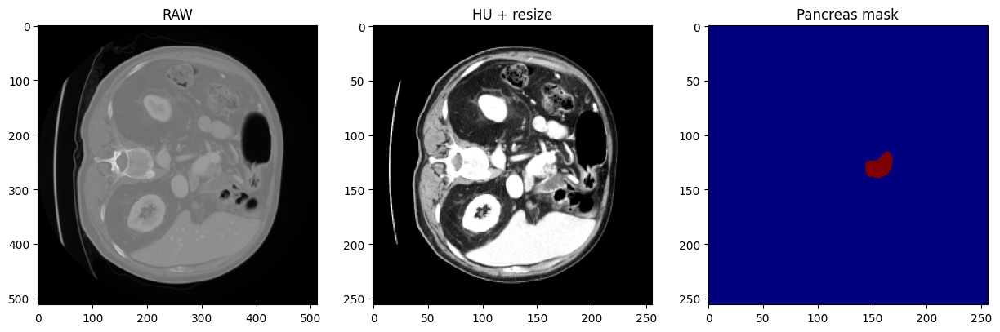

In [ ]:
import cv2
import matplotlib.pyplot as plt

# HU window như lúc train
def hu_window(img):
    img = np.clip(img, -128, 127)
    img = (img + 128) / 255.0
    return img.astype(np.float32)

# lấy 1 slice giữa volume
z = vol.shape[2]//2
slice_raw = vol[:,:,z]

slice_hu = hu_window(slice_raw)
slice_resize = cv2.resize(slice_hu,(256,256))

x = slice_resize[None,...,None]

pred = pancreas_model.predict(x)[0]
mask = np.argmax(pred,-1)

print("Unique mask:", np.unique(mask))

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("RAW")
plt.imshow(slice_raw,cmap='gray')

plt.subplot(1,3,2)
plt.title("HU + resize")
plt.imshow(slice_resize,cmap='gray')

plt.subplot(1,3,3)
plt.title("Pancreas mask")
plt.imshow(mask,cmap='jet')

plt.show()


test nhãn TỤY

In [ ]:
pred = pancreas_model.predict(x)[0]
mask = np.argmax(pred,-1)

print("Unique label:", np.unique(mask))


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Unique label: [0 1]


test nhãn U TỤY

In [ ]:
import cv2
import numpy as np

# mask tụy đã có từ model 1
# mask = np.argmax(pred_pancreas,-1)

# crop ROI theo tụy
coords = np.where(mask==1)

if len(coords[0])==0:
    print("❌ Không phát hiện tụy → không chạy tumor model")
else:
    y1,y2 = coords[0].min(), coords[0].max()
    x1,x2 = coords[1].min(), coords[1].max()

    roi = slice_resize[y1:y2, x1:x2]

    # resize về 128
    roi128 = cv2.resize(roi,(128,128))

    # tạo batch
    x_t = roi128[None,...,None].astype(np.float32)

    print("x_t shape:", x_t.shape)
    print("min/max:", x_t.min(), x_t.max())


x_t shape: (1, 128, 128, 1)
min/max: 0.16789216 1.0


In [ ]:
pred_t = tumor_model.predict(x_t)[0]
mask_t = np.argmax(pred_t,-1)

print("Tumor unique:", np.unique(mask_t))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 899ms/step
Tumor unique: [0]


CHECKLIST AN TOÀN (bắt buộc trước inference)

In [ ]:
print("Input min/max:", x.min(), x.max())
print("Unique mask:", np.unique(mask))


Input min/max: 0.0 1.0
Unique mask: [0 1]


#PHẦN 2: ĐÃ AN TOÀN ĐỂ THỰC HIỆN QUÁ TRÌNH TEST

# CELL 1 – Load model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf

PANCREAS_MODEL_PATH = "/content/drive/MyDrive/models/unet_best_pancreas.keras"
TUMOR_MODEL_PATH    = "/content/drive/MyDrive/models/unet_best_tumor.keras"

pancreas_model = tf.keras.models.load_model(
    PANCREAS_MODEL_PATH, compile=False)

tumor_model = tf.keras.models.load_model(
    TUMOR_MODEL_PATH, compile=False)

print("✅ Models loaded")
print("Pancreas input:", pancreas_model.input_shape)
print("Tumor input   :", tumor_model.input_shape)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Models loaded
Pancreas input: (None, 256, 256, 1)
Tumor input   : (None, 128, 128, 1)


# CELL 2 – Chọn file imagesTs + đọc 3D

In [ ]:
CHỌN ẢNH CT 3D NGẪU NHIÊN

In [ ]:
(NẾU MUỐN CHỌN ẢNH CT 3D NGẪU NHIÊN THÌ CHẠY CODE NÀY)
import os, nibabel as nib
import numpy as np
import random

IMG_TS_DIR = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_goc/imagesTs"

files = sorted(os.listdir(IMG_TS_DIR))
print("Tổng số file:", len(files))
print("5 file đầu:", files[:5])

# ==== CHỌN FILE NGẪU NHIÊN ====
fname = random.choice(files)
path = os.path.join(IMG_TS_DIR, fname)

vol = nib.load(path).get_fdata()

print("FILE (random):", fname)
print("Shape:", vol.shape)
print("Dtype:", vol.dtype)
print("Min/Max:", vol.min(), vol.max())


CHỈ ĐỊNH 1 ẢNH CT 3D CỤ THỂ

In [ ]:
import os, nibabel as nib
import numpy as np

IMG_TS_DIR = "/content/drive/MyDrive/DATA_Pancreas_Segmentation_goc/imagesTs"

files = sorted(os.listdir(IMG_TS_DIR))
print("Tổng số file:", len(files))
print("5 file đầu:", files[:5])

# ==== CHỌN FILE TEST ====
fname = files[0]   # đổi index nếu muốn
path = os.path.join(IMG_TS_DIR, fname)

vol = nib.load(path).get_fdata()

print("FILE:", fname)
print("Shape:", vol.shape)
print("Dtype:", vol.dtype)
print("Min/Max:", vol.min(), vol.max())


Tổng số file: 139
5 file đầu: ['pancreas_002.nii.gz', 'pancreas_003.nii.gz', 'pancreas_007.nii.gz', 'pancreas_008.nii.gz', 'pancreas_009.nii.gz']
FILE: pancreas_002.nii.gz
Shape: (512, 512, 81)
Dtype: float64
Min/Max: -1024.0 1284.0


# CELL 3 – Hàm tiền xử lý chuẩn (GIỐNG lúc train)

In [ ]:
import cv2
import matplotlib.pyplot as plt

def hu_window(img):
    img = np.clip(img, -128, 127)
    img = (img + 128) / 255.0
    return img.astype(np.float32)

def prep_pancreas(img):
    img = hu_window(img)
    img = cv2.resize(img,(256,256))
    return img[...,None]

def prep_tumor(img):
    img = cv2.resize(img,(128,128))
    return img[...,None]


# CELL 4 – Duyệt TẤT CẢ slice + predict tụy

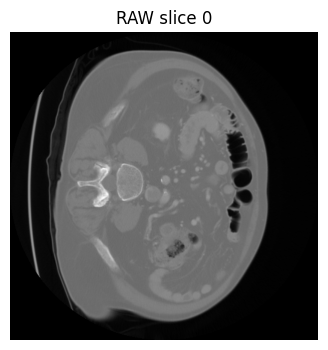

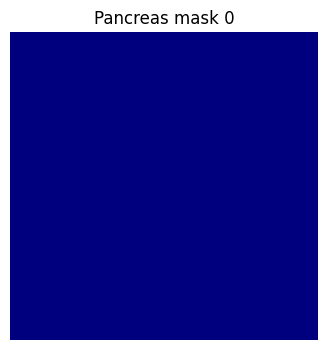

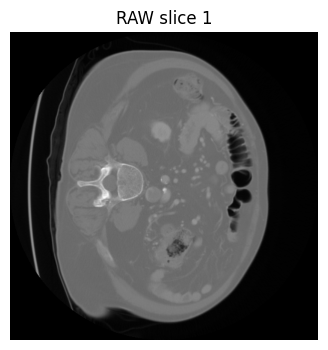

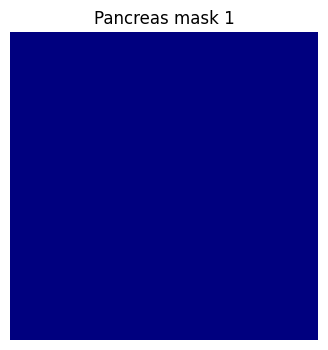

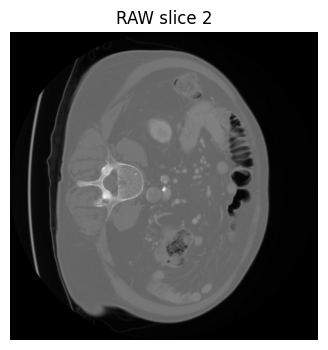

...

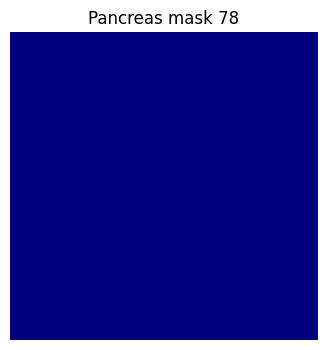

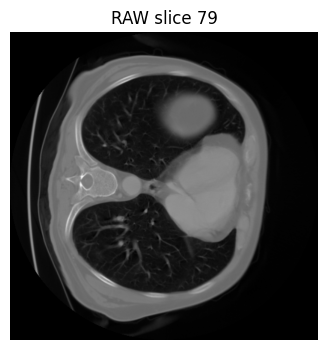

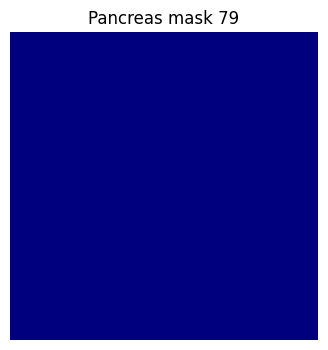

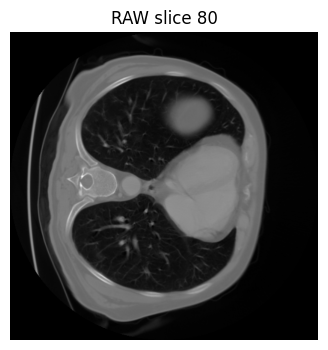

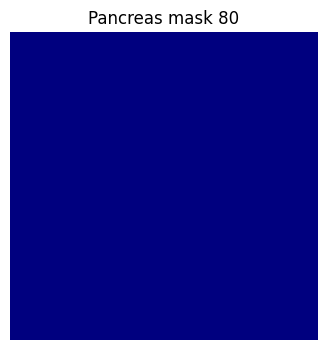

In [ ]:
pancreas_masks = []
tumor_masks = []

cnt_pancreas = 0
cnt_tumor = 0

for z in range(vol.shape[2]):

    raw = vol[:,:,z]

    # ===== HIỂN THỊ SLICE GỐC =====
    plt.figure(figsize=(4,4))
    plt.imshow(raw,cmap="gray")
    plt.title(f"RAW slice {z}")
    plt.axis("off")
    plt.show()

    # ===== PANCREAS =====
    x = prep_pancreas(raw)[None,...]
    pred = pancreas_model.predict(x,verbose=0)[0]
    mask_p = np.argmax(pred,-1)

    if np.any(mask_p==1):
        cnt_pancreas+=1

    pancreas_masks.append(mask_p)

    # ===== HIỂN THỊ MASK TỤY =====
    plt.figure(figsize=(4,4))
    plt.imshow(mask_p,cmap="jet")
    plt.title(f"Pancreas mask {z}")
    plt.axis("off")
    plt.show()

    # ===== ROI TỤY =====
    ys,xs = np.where(mask_p==1)
    if len(xs)==0:
        tumor_masks.append(np.zeros((512,512)))
        continue

    y1,y2 = ys.min(), ys.max()
    x1,x2 = xs.min(), xs.max()

    roi = raw[y1:y2,x1:x2]

    # ===== HIỂN THỊ ROI =====
    plt.figure(figsize=(3,3))
    plt.imshow(roi,cmap="gray")
    plt.title("ROI pancreas")
    plt.axis("off")
    plt.show()

    # ===== TUMOR =====
    x_t = prep_tumor(roi)[None,...]
    pred_t = tumor_model.predict(x_t,verbose=0)[0]
    mask_t = np.argmax(pred_t,-1)

    if np.any(mask_t==1):
        cnt_tumor+=1

    # resize mask u về ảnh gốc
    m_full = np.zeros((512,512))
    m_full[y1:y2,x1:x2] = cv2.resize(
        mask_t,(x2-x1,y2-y1),
        interpolation=cv2.INTER_NEAREST
    )

    tumor_masks.append(m_full)

    # ===== HIỂN THỊ MASK U =====
    plt.figure(figsize=(4,4))
    plt.imshow(m_full,cmap="hot")
    plt.title(f"Tumor mask {z}")
    plt.axis("off")
    plt.show()


# CELL 5 – Overlay (RGB CHUẨN)

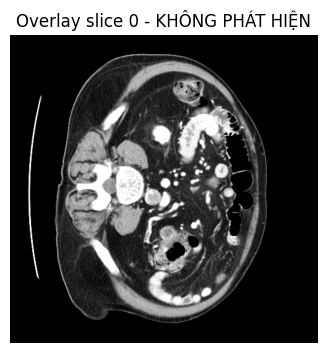

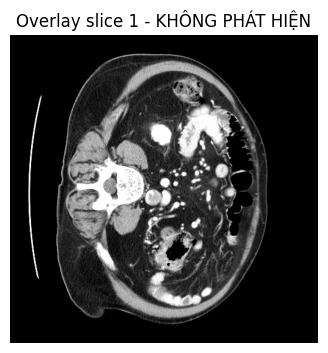

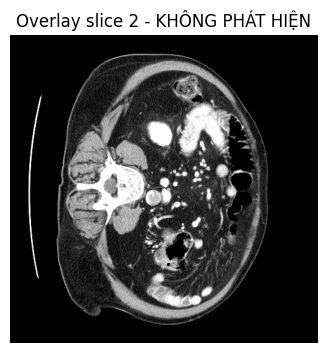

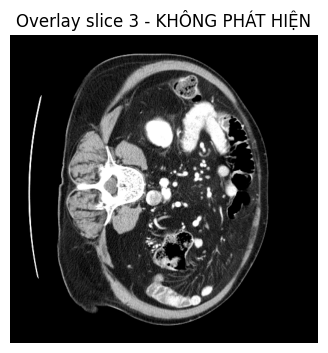

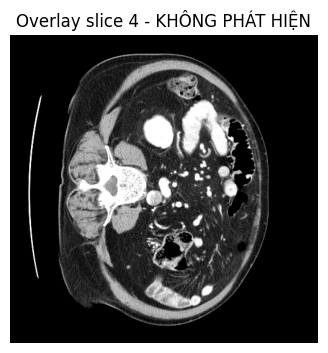

...

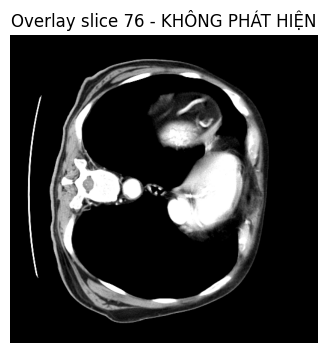

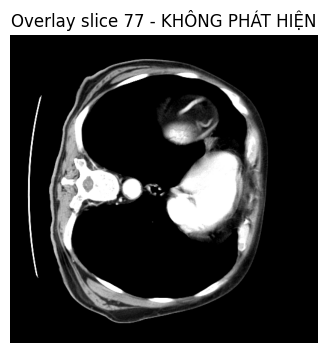

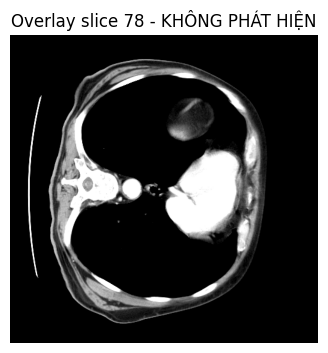

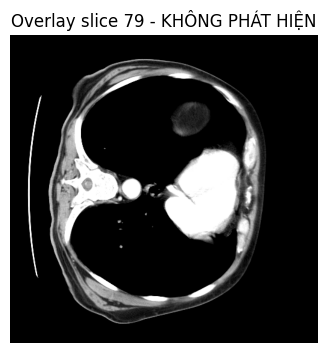

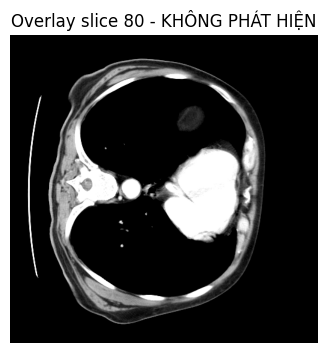

In [ ]:
# ===== CELL 5 – Overlay (RGB CHUẨN) =====
import cv2
import matplotlib.pyplot as plt
import numpy as np

for z in range(vol.shape[2]):

    # ảnh HU -> RGB
    img = hu_window(vol[:,:,z])
    img_rgb = cv2.cvtColor(
        (img*255).astype(np.uint8),
        cv2.COLOR_GRAY2RGB
    )

    has_pancreas = False
    has_tumor    = False

    # ===== TỤY =====
    p = pancreas_masks[z].astype(np.uint8)

    if np.any(p==1):
        cnts,_ = cv2.findContours(
            p, cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            img_rgb, cnts, -1,
            (0,255,255), 2   # ✅ CYAN (RGB)
        )
        has_pancreas = True

    # ===== U =====
    t = tumor_masks[z].astype(np.uint8)

    if np.any(t==1):
        cnts,_ = cv2.findContours(
            t, cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            img_rgb, cnts, -1,
            (255,0,0), 2     # ✅ RED (RGB)
        )
        has_tumor = True

    # ===== LOGIC TITLE =====
    if has_pancreas and has_tumor:
        status = "CÓ TỤY + U"
    elif has_pancreas:
        status = "CÓ TỤY"
    else:
        status = "KHÔNG PHÁT HIỆN"

    # ===== HIỂN THỊ =====
    plt.figure(figsize=(4,4))
    plt.imshow(img_rgb)
    plt.title(f"Overlay slice {z} - {status}")
    plt.axis("off")
    plt.show()


CELL 5B: OVERLAY 1 ẢNH

# CELL 6 – Thống kê

In [ ]:
# ===== CELL 6 — THỐNG KÊ CHUẨN (FINAL) =====

MIN_PIXELS = 10   # NGƯỠNG CHUẨN THEO KẾT QUẢ THỰC

cnt_pancreas = 0
cnt_tumor = 0
valid_tumor_slices = []

# ---- ĐẾM SLICE CÓ TỤY ----
for m in pancreas_masks:
    if np.sum(m) > 0:
        cnt_pancreas += 1

# ---- ĐẾM SLICE CÓ U ----
for i, m in enumerate(tumor_masks):

    area = np.sum(m)

    if area >= MIN_PIXELS:
        cnt_tumor += 1
        valid_tumor_slices.append((i, area))

print("================================")
print("SỐ SLICE CÓ TỤY :", cnt_pancreas)
print("SỐ SLICE CÓ U   :", cnt_tumor)
print("NGƯỠNG (pixel) :", MIN_PIXELS)
print("================================")

print("\nCHI TIẾT SLICE CÓ U:")
for sl, area in valid_tumor_slices:
    print(f"Slice {sl:03d} | tumor pixels = {area}")


SỐ SLICE CÓ TỤY : 43
SỐ SLICE CÓ U   : 22
NGƯỠNG (pixel) : 10

CHI TIẾT SLICE CÓ U:
Slice 011 | tumor pixels = 17.0
Slice 012 | tumor pixels = 24.0
Slice 013 | tumor pixels = 21.0
Slice 014 | tumor pixels = 17.0
Slice 015 | tumor pixels = 25.0
Slice 016 | tumor pixels = 15.0
Slice 017 | tumor pixels = 23.0
Slice 018 | tumor pixels = 19.0
Slice 019 | tumor pixels = 31.0
Slice 020 | tumor pixels = 35.0
Slice 021 | tumor pixels = 44.0
Slice 026 | tumor pixels = 20.0
Slice 027 | tumor pixels = 11.0
Slice 028 | tumor pixels = 12.0
Slice 044 | tumor pixels = 12.0
Slice 045 | tumor pixels = 34.0
Slice 046 | tumor pixels = 42.0
Slice 049 | tumor pixels = 11.0
Slice 051 | tumor pixels = 15.0
Slice 052 | tumor pixels = 51.0
Slice 053 | tumor pixels = 13.0
Slice 054 | tumor pixels = 44.0


# CELL 7 – Visualization

HIỂN THỊ ĐÚNG TỈ LỆ

Tổng slice có tụy: 43
Slice được chọn: [13, 47, 41, 10, 16]

===== SLICE 13 =====


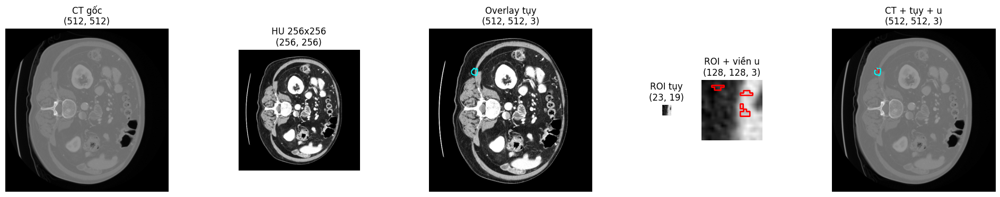


===== SLICE 47 =====


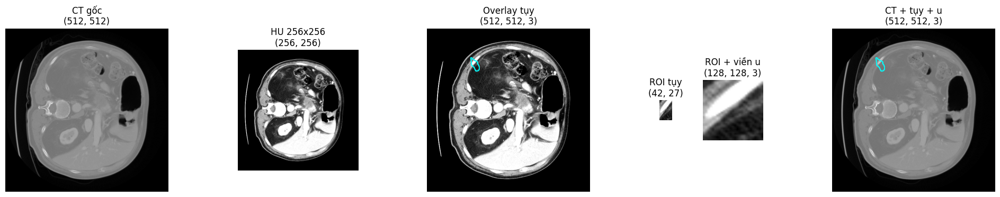


===== SLICE 41 =====


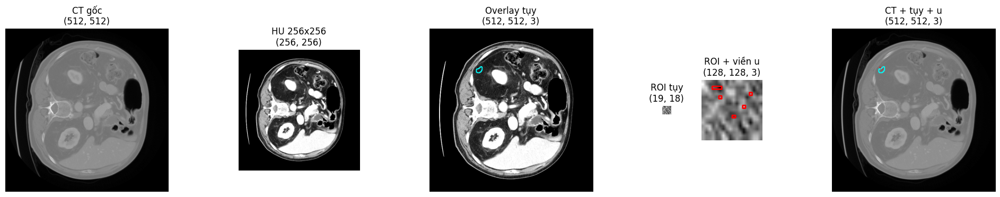


===== SLICE 10 =====


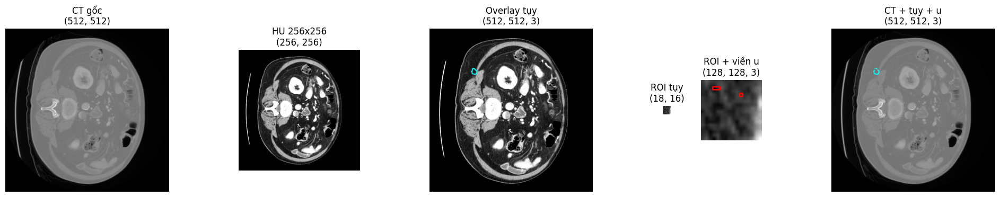


===== SLICE 16 =====


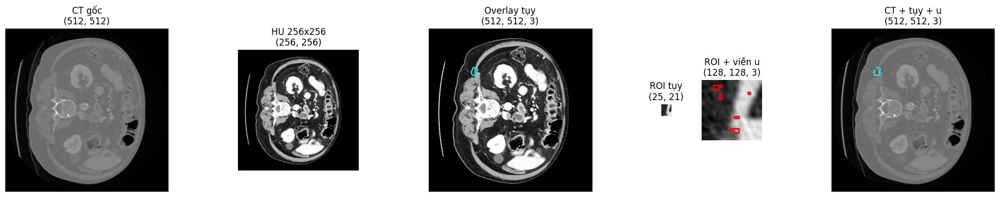

In [ ]:
import random, cv2, numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec

# ================= HÀM VẼ VIỀN =================
def draw_contour(img_gray, mask, color_bgr, thickness=2):

    img = img_gray.copy()
    img = ((img-img.min())/(img.max()-img.min()+1e-8)*255).astype(np.uint8)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    cnts,_ = cv2.findContours(
        mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(img_bgr, cnts, -1, color_bgr, thickness)

    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


# ================= LẤY SLICE CÓ TỤY =================
valid_slices = []
for i,m in enumerate(pancreas_masks):
    if np.any(m==1):
        valid_slices.append(i)

print("Tổng slice có tụy:", len(valid_slices))

random_slices = random.sample(valid_slices, 5)
print("Slice được chọn:", random_slices)


# ================= HIỂN THỊ =================
for sl in random_slices:

    print(f"\n===== SLICE {sl} =====")

    raw = vol[:,:,sl]
    slice_norm = hu_window(raw)

    mask_clean = pancreas_masks[sl]
    roi_on_full = tumor_masks[sl]

    # ----- ROI -----
    ys,xs = np.where(mask_clean==1)

    if len(xs)==0:
        print("⚠ Không có tụy → skip ROI")
        continue

    y1,y2 = ys.min(), ys.max()
    x1,x2 = xs.min(), xs.max()

    roi = slice_norm[y1:y2,x1:x2]
    roi_resize = cv2.resize(roi,(128,128))

    mask_roi = cv2.resize(
        roi_on_full[y1:y2,x1:x2],
        (128,128),
        interpolation=cv2.INTER_NEAREST
    )

    # ================= TẠO 6 ẢNH =================

    img1 = raw

    # ➕ ẢNH MỚI: HU 256x256
    img_hu256 = cv2.resize(slice_norm,(256,256))

    img2 = draw_contour(slice_norm, mask_clean,(255,255,0))
    img3 = roi
    img4 = draw_contour(roi_resize, mask_roi,(0,0,255))
    img5 = draw_contour(raw, mask_clean,(255,255,0))

    cnts,_ = cv2.findContours(
        roi_on_full.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(img5,cnts,-1,(255,0,0),2)

    # ================= TỈ LỆ THẬT =================
    w1 = img1.shape[1]
    wH = img_hu256.shape[1]
    w2 = img2.shape[1]
    w3 = img3.shape[1]
    w4 = img4.shape[1]
    w5 = img5.shape[1]

    ratios = [w1,wH,w2,w3,w4,w5]

    # ================= HIỂN THỊ =================
    fig = plt.figure(figsize=(26,4))
    gs = gridspec.GridSpec(1,6, width_ratios=ratios)

    axs = [plt.subplot(gs[i]) for i in range(6)]

    titles = [
        f"CT gốc\n{img1.shape}",
        f"HU 256x256\n{img_hu256.shape}",
        f"Overlay tụy\n{img2.shape}",
        f"ROI tụy\n{img3.shape}",
        f"ROI + viền u\n{img4.shape}",
        f"CT + tụy + u\n{img5.shape}"
    ]

    images = [img1,img_hu256,img2,img3,img4,img5]
    cmaps  = ['gray','gray',None,'gray',None,None]

    for ax,img,title,cmap in zip(axs,images,titles,cmaps):

        ax.set_title(title)

        if cmap:
            ax.imshow(img,cmap=cmap)
        else:
            ax.imshow(img)

        ax.axis('off')
        ax.set_aspect('equal')

    plt.show()


# CELL 8: IN CẢNH BÁO

In [ ]:
# ====== XÁC ĐỊNH CÓ U HAY KHÔNG ======

MIN_PIXELS = 10   # ngưỡng lọc nhiễu (bạn đang dùng)

ALERT = False
tumor_slices = []

for i, m in enumerate(tumor_masks):
    area = np.sum(m == 1)

    if area > MIN_PIXELS:
        ALERT = True
        tumor_slices.append((i, area))


# ====== IN KẾT QUẢ CHO BÁC SĨ ======

print("\n================ KẾT QUẢ PHÂN TÍCH ================")

if ALERT:
    print("⚠️ KẾT QUẢ: PHÁT HIỆN VÙNG NGHI NGỜ KHỐI U TUYẾN TỤY")
    print("➡ Các slice nghi ngờ:")

    for sl, area in tumor_slices:
        print(f"   - Slice {sl:03d} | Số pixel u = {area}")

    print("\n➡ Khuyến nghị: Bác sĩ nên đánh giá lại trên hình ảnh gốc.")
    print("➡ Kết quả mang tính hỗ trợ, không thay thế chẩn đoán lâm sàng.")

else:
    print("✅ KẾT QUẢ: KHÔNG PHÁT HIỆN TỔN THƯƠNG NGHI NGỜ KHỐI U TUYẾN TỤY")
    print("➡ Tuy nhiên vẫn cần kết hợp đánh giá lâm sàng.")

print("===================================================")



================ KẾT QUẢ PHÂN TÍCH ================
⚠️ KẾT QUẢ: PHÁT HIỆN VÙNG NGHI NGỜ KHỐI U TUYẾN TỤY
➡ Các slice nghi ngờ:
   - Slice 011 | Số pixel u = 17
   - Slice 012 | Số pixel u = 24
   - Slice 013 | Số pixel u = 21
   - Slice 014 | Số pixel u = 17
   - Slice 015 | Số pixel u = 25
   - Slice 016 | Số pixel u = 15
   - Slice 017 | Số pixel u = 23
   - Slice 018 | Số pixel u = 19
   - Slice 019 | Số pixel u = 31
   - Slice 020 | Số pixel u = 35
   - Slice 021 | Số pixel u = 44
   - Slice 026 | Số pixel u = 20
   - Slice 027 | Số pixel u = 11
   - Slice 028 | Số pixel u = 12
   - Slice 044 | Số pixel u = 12
   - Slice 045 | Số pixel u = 34
   - Slice 046 | Số pixel u = 42
   - Slice 049 | Số pixel u = 11
   - Slice 051 | Số pixel u = 15
   - Slice 052 | Số pixel u = 51
   - Slice 053 | Số pixel u = 13
   - Slice 054 | Số pixel u = 44

➡ Khuyến nghị: Bác sĩ nên đánh giá lại trên hình ảnh gốc.
➡ Kết quả mang tính hỗ trợ, không thay thế chẩn đoán lâm sàng.
